# Project Vyapaar | Notebook 04: Hidden Mystery, Marketing & Summary 🕵️📣

**Team:** ____________________

**Lead for this part:** Member 4 (Visualisation & Strategy)

Our own investigation, the marketing bonus and the final management summary.

### How to run this notebook
**On Google Colab:**
1. Upload this notebook to Colab (File → Upload notebook).
2. Click **Runtime → Run all**.
3. When the "Choose Files" button appears, select the 4 data files: `orders.csv`, `products.csv`, `reviews.csv`, `marketing.csv`.

**On Jupyter (laptop):** keep the 4 csv files in the same folder as this notebook (or in a `data` folder next to it) and run all cells.

## Step 0: Load the data

In [1]:
import pandas as pd
import plotly.express as px
import os

# show numbers with 2 decimals and commas
pd.set_option("display.float_format", "{:,.2f}".format)
pd.set_option("display.max_columns", 30)

In [2]:
# This small function finds a csv file whether it is in this folder or in a "data" folder
def find_file(name):
    for folder in ["", "data/", "../data/"]:
        if os.path.exists(folder + name):
            return folder + name
    return None

# If the files are not there we are probably on Google Colab, so ask to upload them
if find_file("orders.csv") is None:
    from google.colab import files
    print("Please upload orders.csv, products.csv, reviews.csv and marketing.csv")
    files.upload()

In [3]:
# encoding="utf-8-sig" removes a hidden character at the start of orders.csv and reviews.csv
orders = pd.read_csv(find_file("orders.csv"), encoding="utf-8-sig")
products = pd.read_csv(find_file("products.csv"))
marketing = pd.read_csv(find_file("marketing.csv"))

# keep_default_na=False stops pandas from turning the word "None" into a blank.
# In reviews, "None" means "no complaint", so we want to keep it.
reviews = pd.read_csv(find_file("reviews.csv"), encoding="utf-8-sig", keep_default_na=False, na_values=[""])

print("orders:", orders.shape)
print("products:", products.shape)
print("reviews:", reviews.shape)
print("marketing:", marketing.shape)

orders: (4001, 14)
products: (121, 7)
reviews: (4001, 5)
marketing: (18, 9)


## Step 1: Clean the data
These are the same cleaning steps as **Notebook 01 (Data Cleaning)**. The reasons for each step are explained there.

In [4]:
# 1. remove exact duplicate rows
orders = orders.drop_duplicates()
products = products.drop_duplicates()
reviews = reviews.drop_duplicates()

# 2. fix the 2 wrongly labelled products
products.loc[products["product_id"] == "P011", "category"] = "Beauty"
products.loc[products["product_id"] == "P074", "subcategory"] = "Small Appliances"

# 3. fix spelling of sales channel
orders["sales_channel"] = orders["sales_channel"].replace("web site", "Website")

# 4. fill the 1 missing discount using: discount = 1 - revenue / (quantity x price)
orders["discount_pct"] = orders["discount_pct"].fillna(
    (1 - orders["revenue_inr"] / (orders["quantity"] * orders["unit_price_inr"])).round(2))

# 5. label blanks instead of deleting them
orders["customer_id"] = orders["customer_id"].fillna("Unknown")
orders["campaign_id"] = orders["campaign_id"].fillna("No campaign")

# 6. text -> dates
orders["order_date"] = pd.to_datetime(orders["order_date"])
marketing["start_date"] = pd.to_datetime(marketing["start_date"])
marketing["end_date"] = pd.to_datetime(marketing["end_date"])

# 7. join everything into one table
df = orders.merge(products, on="product_id").merge(reviews, on="order_id")
df["margin_%"] = df["profit_inr"] / df["revenue_inr"] * 100
print("Clean table:", df.shape)

Clean table: (4000, 25)


---
# Stage 4: OUR HIDDEN MYSTERY 🕵️
## "Where does the money go, and is marketing worth it?"

**Question:** The orders show ₹48 lakh profit, but that ignores marketing. After paying for the 18 campaigns, how much is left? And can we prove the campaigns bring in sales?

### 4.1 Where does the money go?

In [5]:
full_price_sales = (df["quantity"] * df["unit_price_inr"]).sum()
revenue = df["revenue_inr"].sum()
discounts = full_price_sales - revenue
product_cost = df["cost_inr"].sum()
gross_profit = df["profit_inr"].sum()
marketing_spend = marketing["spend_inr"].sum()
left = gross_profit - marketing_spend

print("Sales at full price:  ₹", round(full_price_sales / 100000, 2), "lakh")
print("- Discounts:          ₹", round(discounts / 100000, 2), "lakh")
print("= Revenue:            ₹", round(revenue / 100000, 2), "lakh")
print("- Product cost:       ₹", round(product_cost / 100000, 2), "lakh")
print("= Gross profit:       ₹", round(gross_profit / 100000, 2), "lakh")
print("- Marketing spend:    ₹", round(marketing_spend / 100000, 2), "lakh")
print("= Left after marketing: ₹", round(left / 100000, 2), "lakh")
print()
print("Marketing spend as % of gross profit:", round(marketing_spend / gross_profit * 100), "%")

Sales at full price:  ₹ 203.94 lakh
- Discounts:          ₹ 27.99 lakh
= Revenue:            ₹ 175.95 lakh
- Product cost:       ₹ 127.97 lakh
= Gross profit:       ₹ 47.98 lakh
- Marketing spend:    ₹ 46.99 lakh
= Left after marketing: ₹ 0.98 lakh

Marketing spend as % of gross profit: 98 %


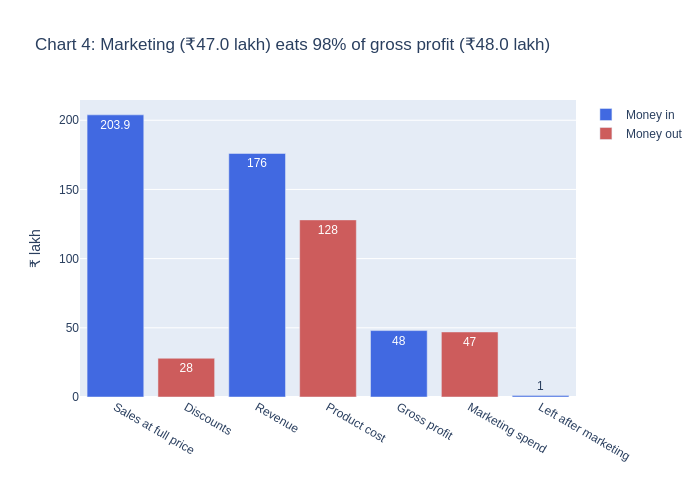

In [6]:
# CHART 4
money = pd.DataFrame({
    "step": ["Sales at full price", "Discounts", "Revenue", "Product cost", "Gross profit", "Marketing spend", "Left after marketing"],
    "lakh": [full_price_sales, discounts, revenue, product_cost, gross_profit, marketing_spend, left],
    "type": ["Money in", "Money out", "Money in", "Money out", "Money in", "Money out", "Money in"],
})
money["lakh"] = (money["lakh"] / 100000).round(1)

fig = px.bar(money, x="step", y="lakh", color="type", text_auto=True,
             category_orders={"step": list(money["step"])},   # keep the bars in our order
             color_discrete_map={"Money in": "royalblue", "Money out": "indianred"},
             title="Chart 4: Marketing (₹47.0 lakh) eats 98% of gross profit (₹48.0 lakh)",
             labels={"step": "", "lakh": "₹ lakh", "type": ""})
fig.show()

Almost **all** of the profit goes on marketing, and this is before delivery costs, salaries and rent (which we don't have). So: **is marketing actually bringing in the sales?**

### 4.2 Were "campaign orders" placed during the campaign?

In [7]:
tagged = df[df["campaign_id"] != "No campaign"]
tagged = tagged.merge(marketing[["campaign_id", "start_date", "end_date"]], on="campaign_id")

def timing(row):
    if row["order_date"] < row["start_date"]:
        return "Before campaign started"
    elif row["order_date"] > row["end_date"]:
        return "After campaign ended"
    else:
        return "During campaign"

tagged["timing"] = tagged.apply(timing, axis=1)
print(tagged["timing"].value_counts())
print()
print((tagged["timing"].value_counts(normalize=True) * 100).round(1))

timing
Before campaign started    1215
After campaign ended       1030
During campaign             283
Name: count, dtype: int64

timing
Before campaign started   48.10
After campaign ended      40.70
During campaign           11.20
Name: proportion, dtype: float64


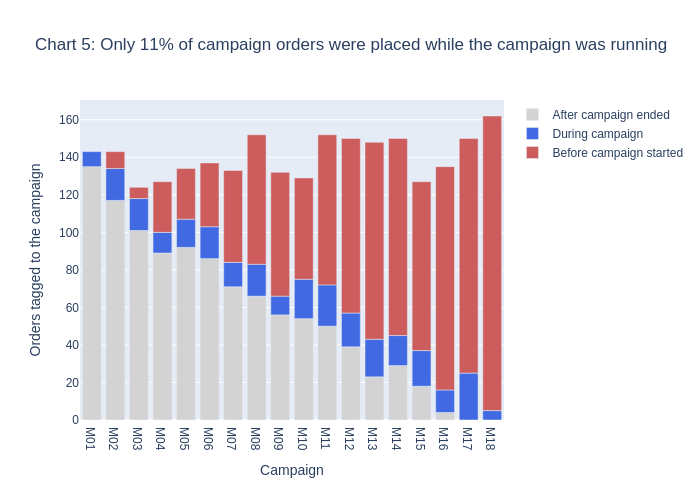

In [8]:
# CHART 5
chart5 = tagged.groupby(["campaign_id", "timing"]).size().reset_index(name="orders")
fig = px.bar(chart5, x="campaign_id", y="orders", color="timing",
             color_discrete_map={"Before campaign started": "indianred", "During campaign": "royalblue", "After campaign ended": "lightgrey"},
             title="Chart 5: Only 11% of campaign orders were placed while the campaign was running",
             labels={"campaign_id": "Campaign", "orders": "Orders tagged to the campaign", "timing": ""})
fig.show()

In [9]:
# Does a campaign that spends more get more orders?
per_campaign = tagged.groupby("campaign_id")["order_id"].count().reset_index(name="tagged_orders")
per_campaign = per_campaign.merge(marketing[["campaign_id", "channel", "spend_inr", "conversions"]], on="campaign_id")
print("Correlation between spend and tagged orders:", round(per_campaign["spend_inr"].corr(per_campaign["tagged_orders"]), 2))
per_campaign

Correlation between spend and tagged orders: 0.19


,campaign_id,tagged_orders,channel,spend_inr,conversions
0,M01,143,Social Media,336420,138
1,M02,143,Search Ads,179161,242
2,M03,124,Email,209553,364
3,M04,127,Influencer,81295,272
4,M05,134,Affiliate,92961,320
5,M06,137,Outdoor,226626,58
6,M07,133,Social Media,413129,373
7,M08,152,Search Ads,410288,118
8,M09,132,Email,340036,482
9,M10,129,Influencer,335202,346


In [10]:
# Marketing says it got this many conversions... how many customers do we have?
known = df[df["customer_id"] != "Unknown"]
first_order = known.groupby("customer_id")["order_date"].min()
h2 = marketing[marketing["start_date"] >= "2025-07-01"]

print("Conversions reported by marketing:", marketing["conversions"].sum())
print("Total customers in our orders:", known["customer_id"].nunique())
print()
print("Spend on campaigns started in Jul-Dec: ₹", round(h2["spend_inr"].sum() / 100000, 2), "lakh")
print("Conversions they reported:", h2["conversions"].sum())
print("NEW customers who first bought in Jul-Dec:", (first_order >= "2025-07-01").sum())

Conversions reported by marketing: 4309
Total customers in our orders: 599

Spend on campaigns started in Jul-Dec: ₹ 20.75 lakh
Conversions they reported: 1596
NEW customers who first bought in Jul-Dec: 15


### Evidence
1. **Marketing (₹47.0 lakh) = 98% of gross profit (₹48.0 lakh).** Less than **₹1 lakh** is left.
2. **48%** of "campaign" orders happened **before the campaign even started**, and only **11%** during it. That is impossible if the tag really means "this campaign brought the sale".
3. Spending more doesn't bring more tagged orders (correlation only 0.19).
4. Marketing reports **4,309 conversions**, but we only have **599 customers**. Campaigns in Jul-Dec spent **₹20.75 lakh**, but only **15 new customers** joined in that time.

### Why management should care
After the product itself, **marketing is the biggest cost**, and right now **nobody can prove it works**. Since almost all customers are repeat buyers, many "conversions" may be people who would have bought anyway.

*Assumptions:* we treat all campaign spend as 2025 cost (2 campaigns run a few weeks into Jan 2026), and we don't know exactly how marketing defines a "conversion".

### Recommendation
1. **Fix tracking:** one coupon code or link per campaign, and don't allow a campaign tag on an order outside the campaign dates.
2. Count a conversion only as a **new customer's first order**.
3. **Test it:** pause one channel in one region for a month and see if sales drop.
4. Cut the weakest channel first (see the Bonus below).

---
# Bonus: Marketing Mystery 📣
Here we use marketing's **own numbers** (remember the doubts above).

In [11]:
ch = marketing.groupby("channel")[["spend_inr", "leads", "conversions"]].sum()
ch["conversion_rate_%"] = ch["conversions"] / ch["leads"] * 100
ch["cost_per_conversion"] = ch["spend_inr"] / ch["conversions"]
ch["share_of_spend_%"] = ch["spend_inr"] / ch["spend_inr"].sum() * 100
ch["share_of_conversions_%"] = ch["conversions"] / ch["conversions"].sum() * 100
ch.sort_values("cost_per_conversion")

,spend_inr,leads,conversions,conversion_rate_%,cost_per_conversion,share_of_spend_%,share_of_conversions_%
channel,,,,,,,
Affiliate,604009,12709,941,7.40,641.88,12.85,21.84
Email,799396,7206,988,13.71,809.11,17.01,22.93
Influencer,729094,11986,714,5.96,"1,021.14",15.51,16.57
Social Media,1122583,13786,1045,7.58,"1,074.24",23.89,24.25
Search Ads,713260,6436,510,7.92,"1,398.55",15.18,11.84
Outdoor,731145,5720,111,1.94,"6,586.89",15.56,2.58


In [12]:
known = df[df["customer_id"] != "Unknown"]
print("Average profit per order: ₹", round(df["profit_inr"].mean()))
print("Average profit per customer per year: ₹", round(known.groupby("customer_id")["profit_inr"].sum().mean()))

Average profit per order: ₹ 1199
Average profit per customer per year: ₹ 8008


**So what?**
- **Outdoor** costs **₹6,587 per conversion**, about **10 times** Affiliate (₹642). It uses **15.6%** of the budget but brings only **2.6%** of conversions.
- **More leads ≠ success.** Influencer and Social Media bring lots of leads, but only 6-8% convert. **Email** converts the best (14%).
- ⚠️ **This is NOT ROI.** For ROI we would need the profit each campaign really caused, and 4.2 showed we can't get that from this data. We can only say that one Outdoor conversion costs more than the profit from one order (₹1,199).
- **Recommendation:** move Outdoor money to Email and Affiliate.

---
# Management Summary 🎯

### Finding 1: Electronics sells but barely makes money
- **Evidence:** 14.5% of revenue but only 3.2% of profit (6.1% margin). 237 Electronics orders lost money. It goes negative at a 20% discount. *(Chart 1, Chart 2)*
- **Implication:** we spend discounts on a category that can't afford them. Beauty (45% of profit) is the real profit engine.
- **Action:** cap Electronics discounts at **10%** (about **+₹1.5 lakh** profit a year), renegotiate supplier costs, and promote Beauty more.

### Finding 2: Big discounts don't increase sales
- **Evidence:** 1.77 units per order at 0% off vs 1.69 at 40% off. Profit per order falls from ₹1,915 to −₹33. ₹28 lakh was given away in discounts. *(Chart 2)*
- **Implication:** the discount strategy is not supported by the data.
- **Action:** set a **maximum discount per category** (no 40% discounts at all; Electronics max 10%) and test any big sale on a small group first.

### Finding 3: East has a delivery problem
- **Evidence:** 38.5% of East orders have a late-delivery complaint vs 12-13% elsewhere. East is 19% of orders but 48% of escalations, and its rating is 3.2 vs 3.9. *(Chart 3)*
- **Implication:** 99% of our customers come back, so customer experience is our biggest asset. Escalations cost money and low ratings put off new customers.
- **Action:** audit the East delivery partner within 30 days, set an on-time target for East, and get `delivery.csv` analysed.

### OUR HIDDEN MYSTERY: Marketing eats 98% of profit and we can't prove it works
- **Question:** after marketing, how much profit is left, and do campaigns really bring in sales?
- **Evidence:** ₹47.0 lakh of marketing vs ₹48.0 lakh gross profit. Only 11% of campaign orders were placed during the campaign (48% before it started). 4,309 "conversions" reported but only 599 customers. *(Chart 4, Chart 5)*
- **Implication:** our biggest controllable cost is not being measured.
- **Recommendation:** fix campaign tracking, count only new customers as conversions, test by pausing a channel, and move Outdoor money (₹6,587 per conversion) to Email/Affiliate.

### Limitations
- We did not have `customers.csv` or `delivery.csv`.
- "Profit" here = revenue − product cost only. Delivery, salaries and rent are not in the data.
- Only one year of data.